In [1]:
import os
import re
import pandas as pd
import numpy as np
import nltk
from nltk.tokenize import sent_tokenize
import spacy
from collections import Counter
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from gensim import corpora
from gensim.models import LdaModel, CoherenceModel, Phrases
from gensim.models.phrases import Phraser
import seaborn as sns
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis

In [2]:
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

True

-------
QUESTION 3.1

In [3]:
#folder containing the research articles
corpus_dir = "../data/research_corpus"

#listing text files sort by article num
files = sorted(
    [f for f in os.listdir(corpus_dir) if f.endswith(".txt")],
    key=lambda f: int(re.search(r"\d+", f).group())
)

#reading each article into records list
articles = []
for f in files:
    with open(os.path.join(corpus_dir, f), encoding="utf-8") as file:
        content = file.read()
        articles.append({
        "article_id": int(re.search(r"\d+", f).group()),
        "filename": f,
        "content": content
        })

In [4]:
#creating the dataframe
articles_df = pd.DataFrame(articles)

#basic size info for each article
articles_df["char_count"] = articles_df["content"].str.len()
articles_df["word_count"] = articles_df["content"].str.split().str.len()

print(articles_df.shape)
articles_df[["article_id", "filename", "char_count", "word_count"]]

(5, 5)


,article_id,filename,char_count,word_count
0,1,research_1.txt,38160,5602
1,2,research_2.txt,16104,2416
2,3,research_3.txt,26154,3828
3,4,research_4.txt,38950,5922
4,5,research_5.txt,26831,4027


In [5]:
#first 300 characters of each article to check topics
for _, row in articles_df.iterrows():
    print(f"--- Article {row['article_id']} ---")
    print(row["content"][:300].replace("\n", " "))
    print()

--- Article 1 ---
The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framewo

--- Article 2 ---
Now I see it, now I don’t: researcher’s position and reflexivity in qualitative research Roni Berger Adelphi University, USA Abstract This article addresses potential effects on reflexivity of researcher’s social position (e.g. gender, age, race, immigration status, sexual orientation), personal exp

--- Article 3 ---
DEVELOPMENTAL RESEARCH: STUDIES OF INSTRUCTIONAL DESIGN AND DEVELOPMENT Rita C. Richey Wayne State University James D. Klein Arizona State University Wayne A. Nelson Southern Illinois University at Edwardsville 41.1 INTRODUCTION The field of instructional technology has traditionally involved a uniq

--- Article 4 ---
Abstract Cronbach’s al

In [6]:
#adding article titles for easier readability
titles = {
    1: "Mixed Methods Research: A Research Paradigm Whose Time Has Come",
    2: "Now I See It, Now I Don't: Researcher's Position and Reflexivity in Qualitative Research",
    3: "Developmental Research: Studies of Instructional Design and Development",
    4: "Cronbach's Alpha in Science Education Research",
    5: "Denzin's Paradigm Shift: Revisiting Triangulation in Qualitative Research"
}

articles_df["title"] = articles_df["article_id"].map(titles)
articles_df[["article_id", "title", "word_count"]]

,article_id,title,word_count
0,1,Mixed Methods Research: A Research Paradigm Wh...,5602
1,2,"Now I See It, Now I Don't: Researcher's Positi...",2416
2,3,Developmental Research: Studies of Instruction...,3828
3,4,Cronbach's Alpha in Science Education Research,5922
4,5,Denzin's Paradigm Shift: Revisiting Triangulat...,4027


---------
QUESTION 3.2

In [7]:
#lightly cleaned text
def light_clean(text):
    #joining wors split across lines with "-"
    text = re.sub(r"(\w)-\s*\n\s*(\w)", r"\1\2", text)

    #replacing remaining line braks wtih spaces to join sentences back
    text = re.sub(r"\s*\n\s*", " ", text)

    #removing in text citations
    text = re.sub(r"\([^()]*\d{4}[a-z]?(,\s*p+\.\s*\d+)?[^()]*\)", " ", text)

    #removing page-only citations
    text = re.sub(r"\(p+\.\s*\d+(\s*[-–]\s*\d+)?\)", " ", text)

    #removing page headers frm journal
    text = re.sub(r"\d*\s*EDUCATIONAL RESEARCHER\s*\d*", " ", text)
    text = re.sub(r"[A-Z]{3,}\s+\d{4}\s+\d+", " ", text)

    #removing footnote numbers at end of words
    text = re.sub(r"(?<=[a-z])([\.,;:]?)\d{1,2}(?=\s)", r"\1", text)

    #removing urls and emails
    text = re.sub(r"http\S+|www\.\S+|\S+@\S+", " ", text)

    #collpasing spaces repeated
    text = re.sub(r"\s+", " ", text).strip()

    #removing spaces left before puncaation where citations removed
    text = re.sub(r"\s+([\.,;:!?])", r"\1", text)
    return text

articles_df["clean_text"] = articles_df["content"].apply(light_clean)

In [8]:
#tokens fully preprocessed
#removing repeated sentences as aritcle 1 contains same passages twice
def remove_duplicate_sentences(text):
    #splitting into sentences and keeping only first run
    seen = set()
    unique = []
    for sent in sent_tokenize(text):
        key = sent.strip().lower()
        if key not in seen:
            seen.add(key)
            unique.append(sent.strip())
    return " ".join(unique)

articles_df["clean_text"] = articles_df["clean_text"].apply(remove_duplicate_sentences)

#comparing word counts before vs after light clean
articles_df["clean_word_count"] = articles_df["clean_text"].str.split().str.len()
articles_df[["article_id", "word_count", "clean_word_count"]]

,article_id,word_count,clean_word_count
0,1,5602,2624
1,2,2416,2241
2,3,3828,3633
3,4,5922,5731
4,5,4027,3706


In [9]:
#checking last 300 char of each cleaned article to look for reference lsit
for _, row in articles_df.iterrows():
    print(f"--- Article {row['article_id']} ---")
    print(row["clean_text"][-300:])
    print()

--- Article 1 ---
ers from different paradigms as they attempt to advance knowledge. Pragmatism also helps to shed light on how research approaches can be mixed fruitfully; the bottom line is that research approaches should be mixed in ways that offer the best opportunities for answering important research questions.

--- Article 2 ---
 of my insider position, I had to be constantly alert and rigorously reflect on how my presence and how I am shaped the conversation as well as explain that while we may have shared an experience, it was different for each, and I want to learn theirs. Finally, coming from the ‘shard experience’ posi

--- Article 3 ---
vide the stimulus for a line of new research, even though these articles themselves are not considered to be research reports themselves. There are many examples today of such work, including explorations of topics such as cognitive task analysis and the nature of design and designer decision making

--- Article 4 ---
ze in a study of teach

In [10]:
#loading spacy english model
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

#raising length limit incase article is very long
nlp.max_length = 2_000_000

def spacy_preprocess(text):
    doc = nlp(text.lower())
    #keeping lemmas of nouns, verbs, etc.
    #removing stopwords, punctuation, numbers and short tokens
    return [
    token.lemma_ for token in doc
    if token.is_alpha
    and not token.is_stop
    and token.pos_ in ["NOUN", "VERB", "ADJ", "ADV"]
    and len(token.lemma_) > 2
    ]

articles_df["tokens"] = articles_df["clean_text"].apply(spacy_preprocess)
articles_df["token_count"] = articles_df["tokens"].str.len()

#comparing size of text at each stage
articles_df[["article_id", "word_count", "clean_word_count", "token_count"]]

,article_id,word_count,clean_word_count,token_count
0,1,5602,2624,1370
1,2,2416,2241,1079
2,3,3828,3633,1856
3,4,5922,5731,2840
4,5,4027,3706,1909


In [11]:
#ten most common tokens in each article to ensure preprocessing kept meaningful words
for _, row in articles_df.iterrows():
    top = Counter(row["tokens"]).most_common(10)
    print(f"Article {row['article_id']}: {', '.join(w for w, c in top)}")

Article 1: research, method, researcher, qualitative, mixed, quantitative, paradigm, purist, reality, social
Article 2: researcher, research, reflexivity, experience, study, position, process, qualitative, effect, share
Article 3: research, development, design, developmental, process, instructional, study, evaluation, type, model
Article 4: alpha, instrument, value, report, cronbach, reliability, science, scale, item, study
Article 5: triangulation, datum, method, study, research, researcher, design, qualitative, multiple, social


---------
QUESTION 3.3

In [12]:
#a1 lightly cleaned text and preprocessed tokens
article1_text = articles_df.loc[articles_df["article_id"] == 1, "clean_text"].iloc[0]
article1_tokens = articles_df.loc[articles_df["article_id"] == 1, "tokens"].iloc[0]

#word frequencies scaled so mode word weight is 1
word_freq = Counter(article1_tokens)
max_freq = max(word_freq.values())
word_weights = {word: count / max_freq for word, count in word_freq.items()}

#splitting article into sentences
sentences = sent_tokenize(article1_text)

#scoring each by ave weight of its meaningful words
sentence_scores = []
for sent in sentences:
    sent_tokens = spacy_preprocess(sent)
    #skipping very short sentence as often headings/fragments
    if len(sent_tokens) < 8:
        sentence_scores.append(0)
        continue
    score = sum(word_weights.get(w, 0) for w in sent_tokens) / len(sent_tokens)
    sentence_scores.append(score)

#picking top 5 n sentences and putting back in original order
top_n = 5
top_idx = sorted(np.argsort(sentence_scores)[::-1][:top_n])
summary = " ".join(sentences[i] for i in top_idx)

print(f"Original: {len(sentences)} sentences, {len(article1_text.split())} words")
print(f"Summary: {top_n} sentences, {len(summary.split())} words")
print(f"Compression: { len(summary.split()) / len(article1_text.split()):.1%} of the original length")
print()
print(summary)

Original: 79 sentences, 2624 words
Summary: 5 sentences, 111 words
Compression: 4.2% of the original length

Our purpose in writing this article is to present mixed methods research as the third research paradigm in educational research. We hope the field will move beyond quantitative versus qualitative research arguments because, as recognized by mixed methods research, both quantitative and qualitative research are important and useful. Mixed methods research as the third research paradigm can also help bridge the schism between quantitative and qualitative research. Although many research procedures or methods typically have been linked to certain paradigms, this linkage between research paradigm and research methods is neither sacrosanct nor necessary. We contend that epistemological and paradigmatic ecumenicalism is within reach in the research paradigm of mixed methods research.


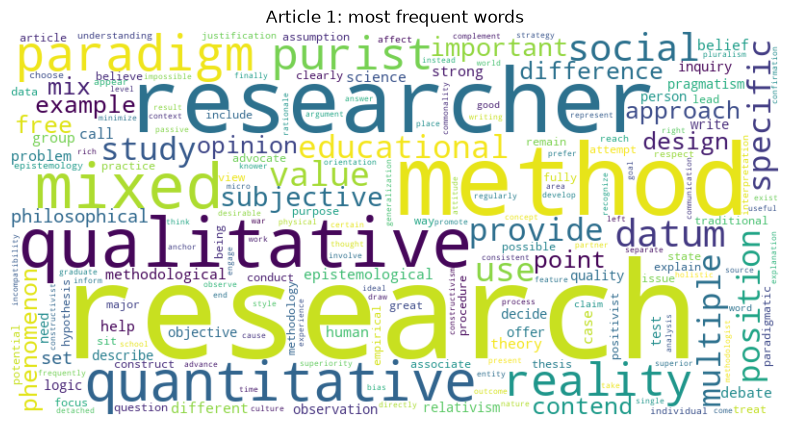

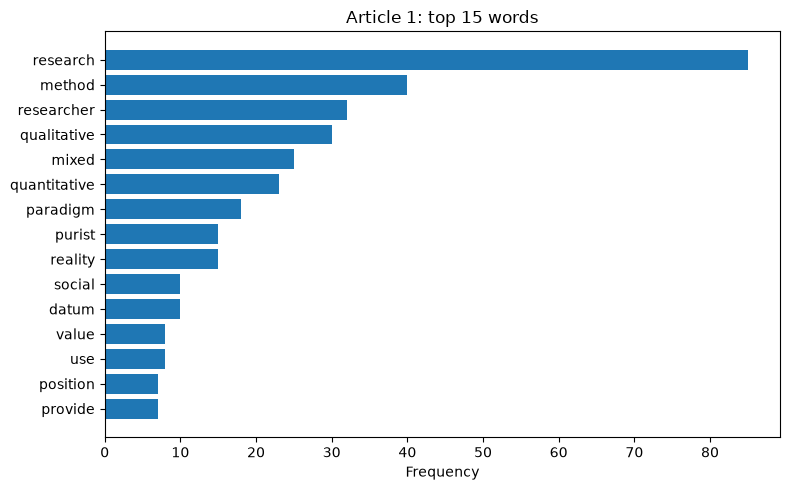

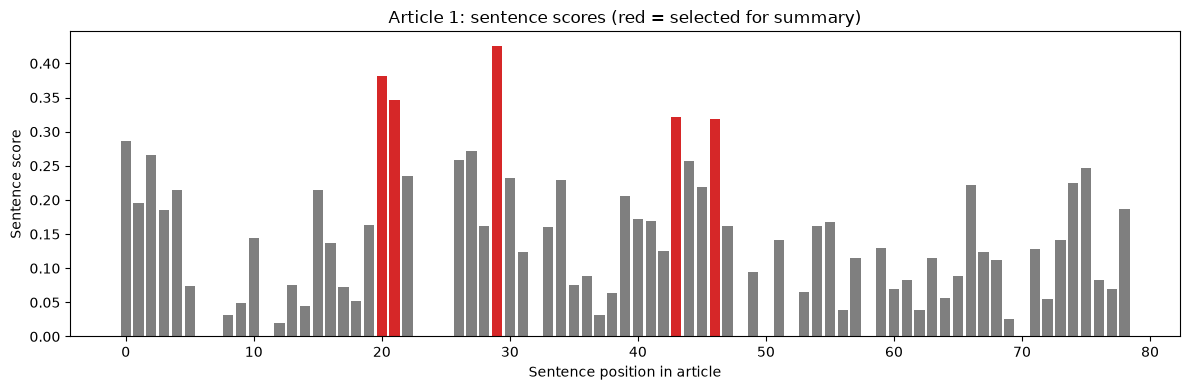

In [13]:
#visualising word cloud of most frequent words in article 1
wc = WordCloud(width=800, height=400, background_color="white").generate_from_frequencies(word_freq)
plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Article 1: most frequent words")
plt.show()

#bar chart of 15 most frequent words
top_words = word_freq.most_common(15)
plt.figure(figsize=(8, 5))
plt.barh([w for w, c in top_words][::-1], [c for w, c in top_words][::-1])
plt.xlabel("Frequency")
plt.title("Article 1: top 15 words")
plt.tight_layout()
plt.show()

#score of every sentences (ones chosen for summary = highlighted)
colours = ["tab:red" if i in top_idx else "tab:grey" for i in range(len(sentences))]
plt.figure(figsize=(12, 4))
plt.bar(range(len(sentences)), sentence_scores, color= colours)
plt.xlabel("Sentence position in article")
plt.ylabel("Sentence score")
plt.title("Article 1: sentence scores (red = selected for summary)")
plt.tight_layout()
plt.show()

-----------
QUESTION 3.4

In [14]:
#textrank function

def textrank_summary(text, n_sentences=3, min_tokens=8):
    #splitting into sentences and preprocssing each with spacy function from 3.2
    all_sentences = sent_tokenize(text)
    processed = [spacy_preprocess(s) for s in all_sentences]

    #keeping only sentence with enough meaningful words
    noise_pattern = r"Keywords|Abstract|Journal of|University|⇒"
    keep = [
        i for i, toks in enumerate(processed)
        if len(toks) >= min_tokens
        and len(all_sentences[i].split()) <= 60
        and not re.search(noise_pattern, all_sentences[i])
    ]
    sentences = [all_sentences[i] for i in keep]
    sent_texts = [" ".join(processed[i]) for i in keep]

    #tfidf vecotr for each then similarity between every pair
    tfidf_matrix = TfidfVectorizer().fit_transform(sent_texts)
    sim_matrix = cosine_similarity(tfidf_matrix)
    np.fill_diagonal(sim_matrix, 0)

    #building graph and scoring sentences 
    graph = nx.from_numpy_array(sim_matrix)
    scores = nx.pagerank(graph)

    #top sentences back in og order
    top_idx = sorted(sorted(scores, key=scores.get, reverse=True)[:n_sentences])
    summary = " ".join(sentences[i] for i in top_idx)

    return summary, sentences, scores, sim_matrix, top_idx

In [15]:
#running textrank on each reminaing article
summaries = []
textrank_outputs = {}

for _, row in articles_df[articles_df["article_id"] !=1].iterrows():
    summary, sents, scores, sim, top_idx = textrank_summary(row["clean_text"], n_sentences=3)
    textrank_outputs[row["article_id"]] = (sents, scores, sim, top_idx)
    summaries.append({
    "article_id": row["article_id"],
    "title": row["title"],
    "summary": summary,
    "original_words": len(row["clean_text"].split()),
    "summary_words": len(summary.split())
    })

summary_df = pd.DataFrame(summaries)
summary_df["compression"] = summary_df["summary_words"] / summary_df["original_words"]

#printing each articles summary
for _, row in summary_df.iterrows():
    print(f"=== Article {row['article_id']}: {row['title']} ===")
    print(row["summary"])
    print()

#aggregating the four summaries into one
agg_summary = "\n\n".join(
    f"Article {r['article_id']} ({r['title']}): {r['summary']}" for _, r in summary_df.iterrows()
)
print(summary_df[["article_id", "original_words", "summary_words", "compression"]].round(3))

=== Article 2: Now I See It, Now I Don't: Researcher's Position and Reflexivity in Qualitative Research ===
Relative to the contribution of reflexivity to keeping the process of research ethical, Pillow stated that ‘reflexivity is situating the researcher as non-exploitative and compassionate toward the research subjects’, thus helping to address concerns regarding negative effects of power in researcher–researched relationships. Reflexivity helps maintain the ethics of the relationship between researcher and research by ‘decolonizing’ the discourse of the ‘other’ and securing that while interpretation of findings is always done through the eyes and cultural standards of the researcher, the effects of the latter on the research process is monitored. While the importance of reflexivity, its roles, purposes, and strategies to enhance it have been discussed and demonstrated, the relationship between reflexivity and the position of the researcher vis-à-vis the phenomenon under study has be

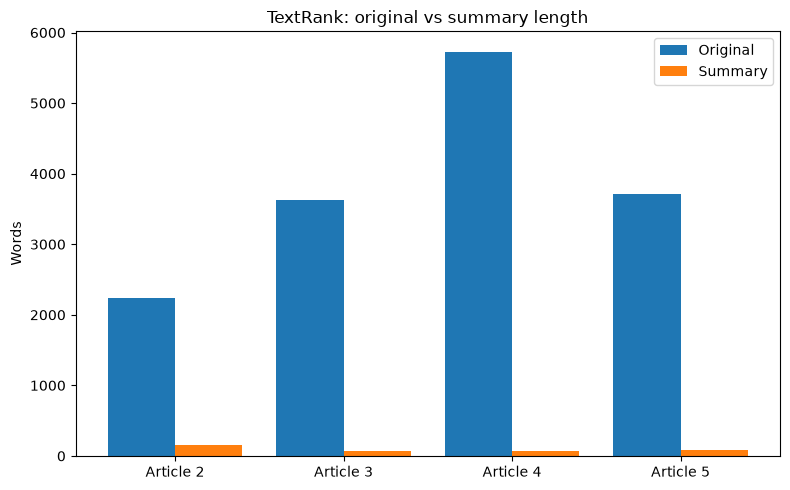

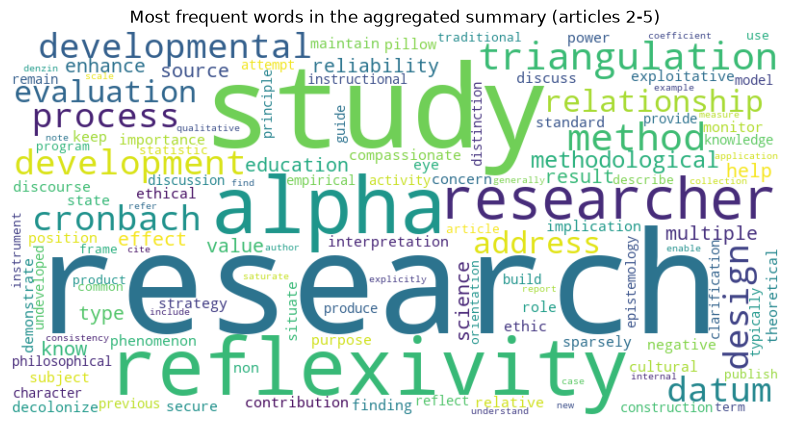

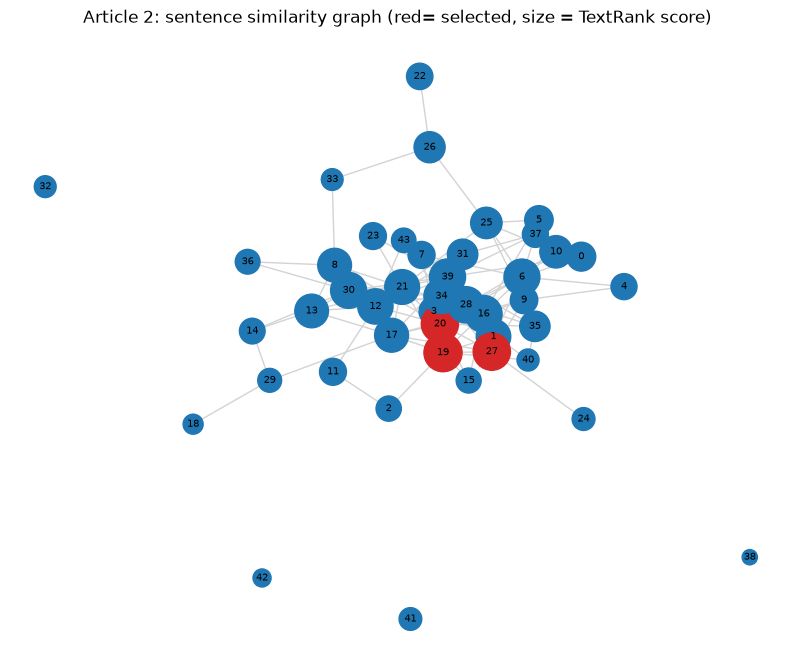

In [16]:
#visualising original vs summary length for each article
x = np.arange(len(summary_df))
plt.figure(figsize=(8, 5))
plt.bar(x - 0.2, summary_df["original_words"], width=0.4, label="Original")
plt.bar(x + 0.2, summary_df["summary_words"], width=0.4, label="Summary")
plt.xticks(x, [f"Article {i}" for i in summary_df["article_id"]])
plt.ylabel("Words")
plt.title("TextRank: original vs summary length")
plt.legend()
plt.tight_layout()
plt.show()

#word cloud of the agg summary
agg_tokens = spacy_preprocess(" ".join(summary_df["summary"]))
wc = WordCloud(width=800, height=400, background_color="white").generate_from_frequencies(Counter(agg_tokens))
plt.figure(figsize=(10, 5))
plt.imshow(wc , interpolation="bilinear")
plt.axis("off")
plt.title("Most frequent words in the aggregated summary (articles 2-5)")
plt.show()

#sentence sumilarity networks for a2
sents, scores, sim, top_idx = textrank_outputs[2]
graph = nx.from_numpy_array(np.where(sim > 0.1, sim, 0))
plt.figure(figsize=(10, 8))
pos = nx.spring_layout(graph, seed=42)
node_sizes = [scores[i] * 20000 for i in graph.nodes]
node_colours = ["tab:red" if i in top_idx else "tab:blue" for i in graph.nodes]
nx.draw_networkx(graph, pos, node_size=node_sizes, node_color=node_colours, with_labels=True, font_size=7,
                 edge_color="lightgrey")
plt.title("Article 2: sentence similarity graph (red= selected, size = TextRank score)")
plt.axis("off")
plt.show()



----------
QUESTION 4
-----------

--------
QUESTION 4.1

In [17]:
#splitting each article into chunks of 5 sentences
chunk_size = 5 
chunks = []
for _, row in articles_df.iterrows():
    sents = sent_tokenize(row["clean_text"])
    for start in range(0, len(sents), chunk_size):
        chunks.append({
            "article_id": row["article_id"],
            "chunk_id": start // chunk_size,
            "text": " ".join(sents[start:start + chunk_size])
        })

chunks_df = pd.DataFrame(chunks)
print("Number of chunks (documents):", len(chunks_df))
print(chunks_df["article_id"].value_counts().sort_index())

Number of chunks (documents): 131
article_id
1    16
2    13
3    32
4    37
5    33
Name: count, dtype: int64


In [18]:
#preprocessing each chunk with the spaCy function form 3.2
chunks_df["tokens"] = chunks_df["text"].apply(spacy_preprocess)

#extra stopwords which are generic words that appear across all articles which would make topics overlap
lda_stopwords = {"research", "researcher", "study", "article", "author", "use", "datum",
                 "fusch_fusch", "ness_journal"}
chunks_df["tokens"] = chunks_df["tokens"].apply(lambda toks: [t for t in toks if t not in lda_stopwords])

#detecting common two-word phrases and joining them as one
bigram = Phraser(Phrases(chunks_df["tokens"], min_count=3, threshold=10))
chunks_df["tokens"] = chunks_df["tokens"].apply(lambda toks: bigram[toks])
chunks_df["tokens"] = chunks_df["tokens"].apply(lambda toks: [t for t in toks if t not in lda_stopwords])
texts = chunks_df["tokens"].tolist()

#building dictionary
dictionary = corpora.Dictionary(texts)
print(f"Dictionary length before filtering: {len(dictionary)}")

#removing words in fewer than 2 chunks or more than 50% of chunks 
dictionary.filter_extremes(no_below=2, no_above=0.5)
print(f"Dictionary length after filtering: {len(dictionary)}")

#bow corpus
corpus = [dictionary.doc2bow(t) for t in texts]

#examples of the detected two word phrases
phrases = sorted({t for toks in texts for t in toks if "_" in t})
print("Detected phrases:", phrases[:30])

Dictionary length before filtering: 1946
Dictionary length after filtering: 1005
Detected phrases: ['acceptable_value', 'alpha_statistic', 'alpha_value', 'answer_question', 'blend_design', 'case_design', 'collection_method', 'conceptual_framework', 'construct_validity', 'context_specific', 'cronbach_alpha', 'data_collection', 'data_triangulation', 'design_development', 'development_evaluation', 'development_process', 'diagnostic_instrument', 'explicit_reference', 'factor_analysis', 'human_being', 'instructional_design', 'instructional_development', 'instructional_psychology', 'instructional_system', 'instructional_technology', 'instrument_quality', 'internal_consistency', 'knowledge_production', 'knowledge_understanding', 'methodological_triangulation']


Topics: 2, coherence: 0.338
Topics: 3, coherence: 0.534
Topics: 4, coherence: 0.486
Topics: 5, coherence: 0.448
Topics: 6, coherence: 0.388
Topics: 7, coherence: 0.492
Topics: 8, coherence: 0.485
Topics: 9, coherence: 0.444
Topics: 10, coherence: 0.474


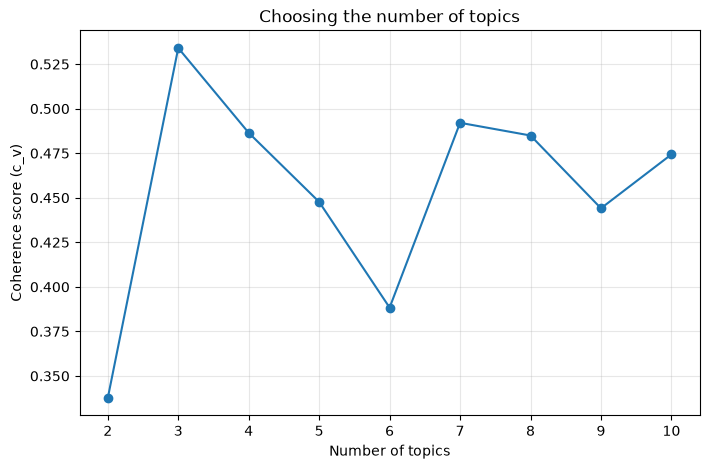

In [19]:
#training an LDA model for each num topuics and measurign its cv coherence
topic_range = range(2, 11)
coherence_scores = []

for k in topic_range:
    model = LdaModel(corpus=corpus, id2word=dictionary, num_topics=k,
                     random_state=42, passes=20, alpha="auto", eta="auto")
    cm = CoherenceModel(model=model, texts=texts, dictionary=dictionary, coherence="c_v")
    coherence_scores.append(cm.get_coherence())
    print(f"Topics: {k}, coherence: {coherence_scores[-1]:.3f}")

#plotting coherence against the num topics
plt.figure(figsize=(8, 5))
plt.plot(list(topic_range), coherence_scores, marker="o")
plt.xlabel("Number of topics")
plt.ylabel("Coherence score (c_v)")
plt.title("Choosing the number of topics")
plt.grid(alpha=0.3)
plt.show()

In [20]:
#comparing topics made with 3 and 8 topics
for k in [3, 8]:
    model = LdaModel(corpus=corpus, id2word=dictionary, num_topics=k,
                     random_state=42, passes=20, alpha="auto", eta="auto")
    print(f"===== {k} topics =====")
    for topic_id, words in model.show_topics(num_topics=k, num_words=10, formatted=False):
        print(f"Topic {topic_id}: {', '.join(w for w, p in words)}")
    print()

===== 3 topics =====
Topic 0: qualitative, reflexivity, triangulation, method, participant, social, position, experience, knowledge, process
Topic 1: development, process, design, developmental, triangulation, mixed_method, method, evaluation, field, type
Topic 2: alpha, report, instrument, scale, item, reliability, cronbach_alpha, value, measure, test

===== 8 topics =====
Topic 0: qualitative, validity, participant, high, value, acceptable, concept, offer, represent, descriptor
Topic 1: developmental, process, development, evaluation, design, field, model, knowledge, type, term
Topic 2: alpha, instrument, report, cronbach_alpha, scale, reliability, item, science_education, test, measure
Topic 3: reflexivity, qualitative, self, process, strategy, address, interview, effect, knowledge, position
Topic 4: reading, development, orientation, example, design, change, process, issue, journal, case_design
Topic 5: mixed_method, purist, paradigm, design, quantitative, approach, different, real

In [21]:
#training finakl LDA model with chosen num of topics
best_k = 8
lda_final = LdaModel(corpus=corpus, id2word=dictionary, num_topics=best_k,
                     random_state=42, passes=20, alpha="auto", eta="auto")

final_coherence = CoherenceModel(model=lda_final, texts=texts, dictionary=dictionary, coherence="c_v").get_coherence()
print(f"Final model coherence: {final_coherence:.3f}")

for topic_id, words in lda_final.show_topics(num_topics=best_k, num_words=10, formatted=False):
    print(f"Topic {topic_id}: {', '.join(w for w, p in words)}")

Final model coherence: 0.485
Topic 0: qualitative, validity, participant, high, value, acceptable, concept, offer, represent, descriptor
Topic 1: developmental, process, development, evaluation, design, field, model, knowledge, type, term
Topic 2: alpha, instrument, report, cronbach_alpha, scale, reliability, item, science_education, test, measure
Topic 3: reflexivity, qualitative, self, process, strategy, address, interview, effect, knowledge, position
Topic 4: reading, development, orientation, example, design, change, process, issue, journal, case_design
Topic 5: mixed_method, purist, paradigm, design, quantitative, approach, different, reality, qualitative, method
Topic 6: triangulation, method, qualitative, denzin, social_change, methodological_triangulation, example, concept, point, multiple
Topic 7: value, theory, internal_consistency, item, reliability, different, term, include, biology, result


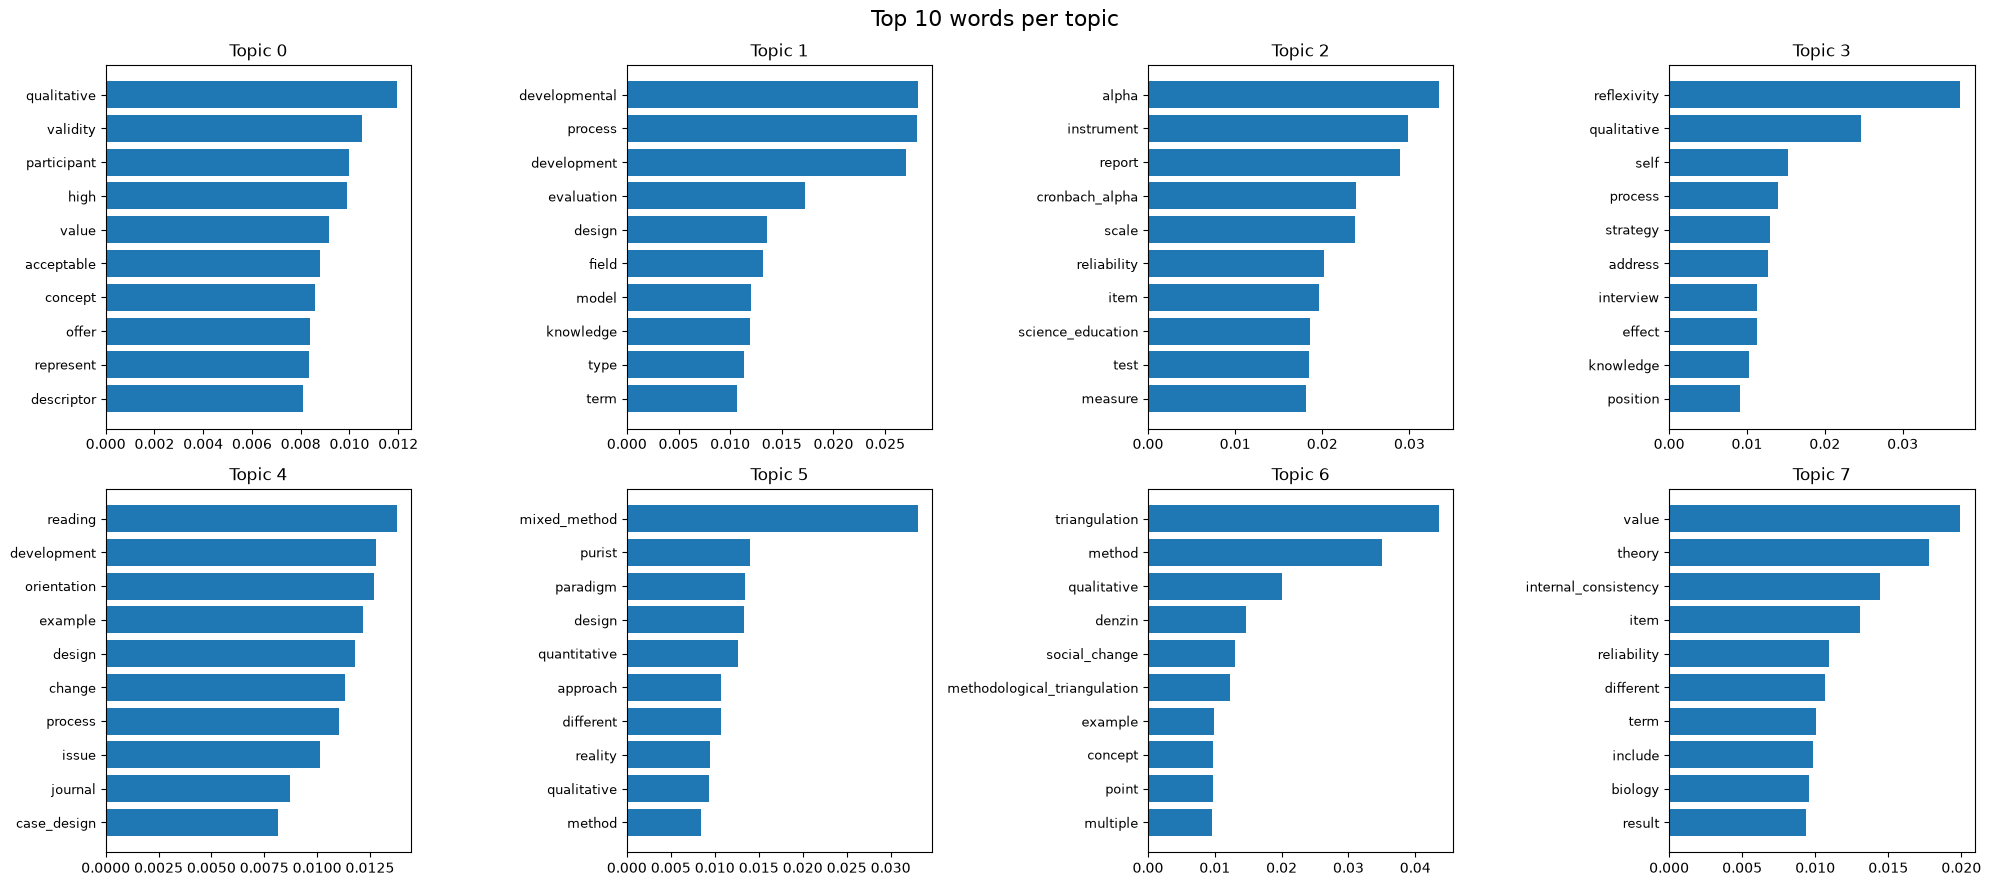

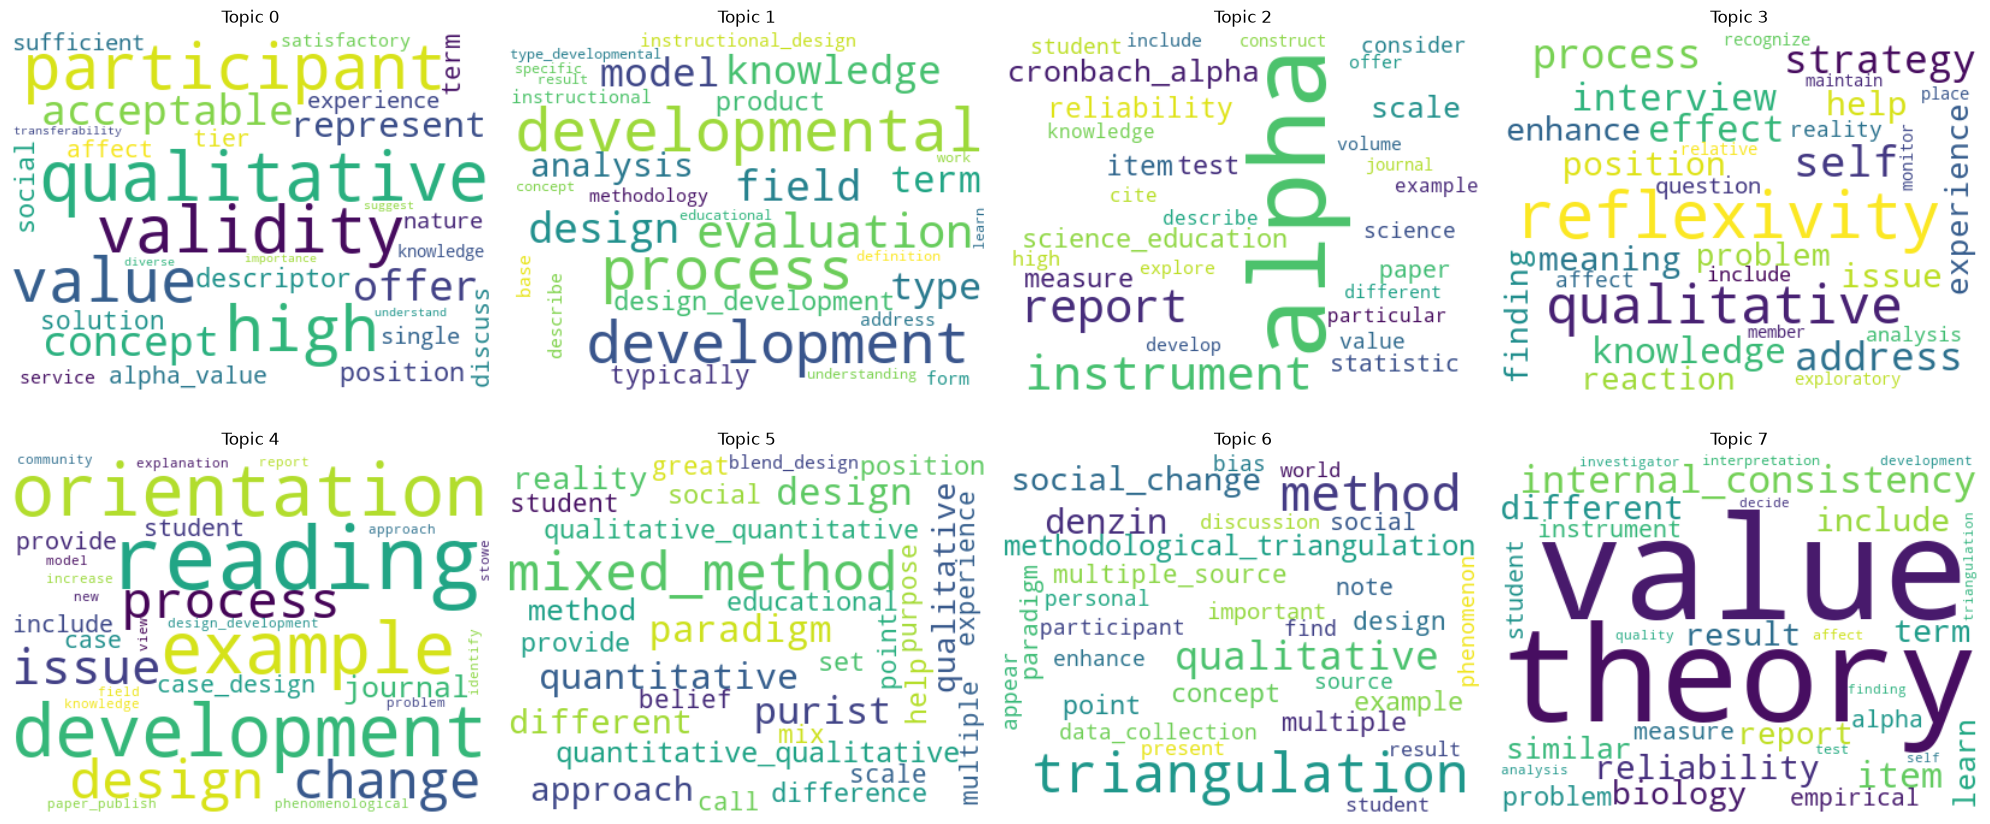

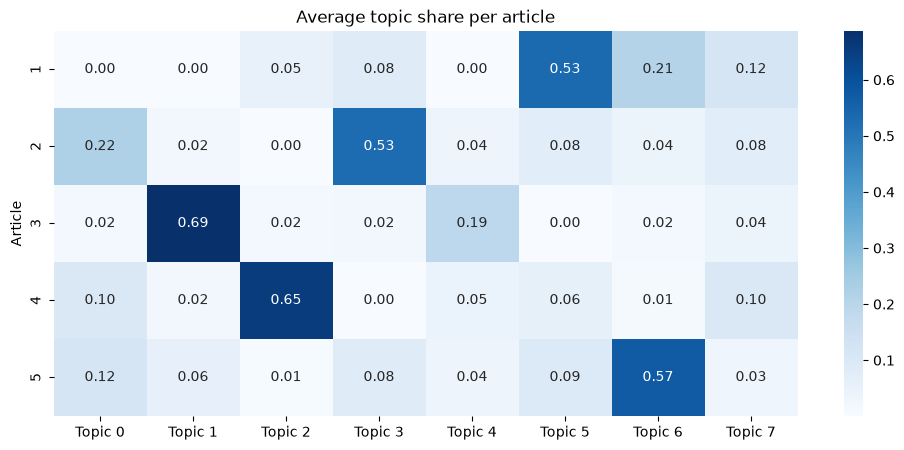

In [22]:
#bar chart of the top 10 words in each topic
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for topic_id, ax in enumerate(axes.flatten()):
    words, weights = zip(*lda_final.show_topic(topic_id, topn=10))
    ax.barh(words[::-1], weights[::-1])
    ax.set_title(f"Topic {topic_id}")
    ax.tick_params(axis="y", labelsize=9)
plt.suptitle("Top 10 words per topic", fontsize=16)
plt.tight_layout()
plt.show()

#word cloud for each topic
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for topic_id, ax in enumerate(axes.flatten()):
    wc = WordCloud(width=400, height=300, background_color="white").generate_from_frequencies(
        dict(lda_final.show_topic(topic_id, topn=30)))
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(f"Topic {topic_id}")
    ax.axis("off")
plt.tight_layout()
plt.show()

#average share of each topic in each article 
doc_topics = np.zeros((len(corpus), best_k))
for i, bow in enumerate(corpus):
    for topic_id, prob in lda_final.get_document_topics(bow, minimum_probability=0):
        doc_topics[i, topic_id] = prob

topic_by_article = pd.DataFrame(doc_topics, columns=[f"Topic {i}" for i in range(best_k)])
topic_by_article["article_id"] = chunks_df["article_id"].values
topic_by_article = topic_by_article.groupby("article_id").mean()

plt.figure(figsize=(12, 5))
sns.heatmap(topic_by_article, annot=True, fmt=".2f", cmap="Blues")
plt.title("Average topic share per article")
plt.ylabel("Article")
plt.show()

-----------------
QUESTION 4.2

In [23]:
#allowing interactive chart to displau in notebook
pyLDAvis.enable_notebook()

#visualising from final model
vis = gensimvis.prepare(lda_final, corpus, dictionary, sort_topics=False)

#saving as HTML file for GitHub
pyLDAvis.save_html(vis, "../outputs/lda_intertopic_map.html")

vis

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0      0.019235  0.111937       1        1   8.356865
1     -0.048057 -0.204153       2        1  16.881550
2      0.260756  0.002912       3        1  22.360214
3     -0.108148  0.097553       4        1   9.573224
4     -0.050158 -0.118471       5        1   7.306290
5     -0.067267  0.025635       6        1  12.213459
6     -0.106852  0.071820       7        1  16.230848
7      0.100493  0.012766       8        1   7.077550, topic_info=              Term       Freq      Total Category  logprob  loglift
396  triangulation  53.000000  53.000000  Default  30.0000  30.0000
317          alpha  55.000000  55.000000  Default  29.0000  29.0000
461    reflexivity  27.000000  27.000000  Default  28.0000  28.0000
27    mixed_method  33.000000  33.000000  Default  27.0000  27.0000
624  developmental  34.000000  34.000000  Default  26.0000  26.0000
..             ...        ...        ...      ...      ...      ...
345           self   2.524970  14.093324   Topic8  -5.2505   0.9288
323    development   2.578834  48.621010   Topic8  -5.2294  -0.2885
396  triangulation   2.419111  53.221971   Topic8  -5.2933  -0.4428
204       analysis   2.419057  28.966132   Topic8  -5.2934   0.1655
325        finding   2.418950  12.283186   Topic8  -5.2934   1.0233

[491 rows x 6 columns], token_table=      Topic      Freq              Term
term                                   
805       1  0.440643        acceptable
805       3  0.528771        acceptable
792       1  0.395636  acceptable_value
792       2  0.395636  acceptable_value
57        6  0.775317            accord
...     ...       ...               ...
171       7  0.626343             world
579       2  0.145293              year
579       3  0.653817              year
579       4  0.072646              year
579       5  0.072646              year

[990 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4, 5, 6, 7, 8])

In [24]:
import sklearn, pandas, numpy, nltk, joblib, streamlit
for lib in [sklearn, pandas, numpy, nltk, joblib, streamlit]:
    print(f"{lib.__name__}=={lib.__version__}")

sklearn==1.9.0
pandas==2.3.3
numpy==2.3.5
nltk==3.9.2
joblib==1.5.2
streamlit==1.51.0
